<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QRF_HealthcareIoT_AlHawawreh2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kernel-based quantum random forest with local differential privacy for IoT healthcare attack detection: Al-Hawawreh and Hossain (2025) step by step

This notebook re-implements, runs and checks the detection model of

> Muna Al-Hawawreh and M. Shamim Hossain, "A Human-Centered Quantum Machine Learning Framework for Attack Detection in
> IoT-Based Healthcare Industry 5.0", *IEEE Internet of Things Journal*, vol. 12, no. 22, pp. 46065-46074, 15 November 2025.
> DOI 10.1109/JIOT.2025.3565687

The paper publishes no code. Everything below is written from its description of the pipeline and from the kernel-based
quantum random forest (QRF) paper it cites (Srikumar, Hill and Hollenberg, *Quantum Machine Intelligence* 6, 2024).

**What the notebook does.** It downloads the WUSTL-EHMS-2020 healthcare-IoT dataset (one of the paper's two datasets, and
the only one that is publicly downloadable), applies the paper's privacy layer (a standard scaler whose mean is perturbed
with Laplace noise, privacy budget epsilon = 1, the paper's Algorithm 1), reduces the 30 features to 6 principal components
and trains a **kernel-based quantum random forest**: 3 quantum decision trees of depth 4 whose every split is a linear SVM
trained on Nystroem-approximated *quantum kernel* features computed from 5 random landmark points on 6 qubits. The same
inputs are given to a random forest, an RBF-SVM, logistic regression and naive Bayes. The paper's Fig. 3 (feature
distributions before and after the privacy layer) and Fig. 5 (MCC) are redrawn, its time/memory formulas (Table III) are
re-evaluated, and the human-in-the-loop idea (active learning with an analyst who relabels uncertain flows) is shown in a
small extension. The last section puts the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The setup cell installs a
pinned Qiskit (used for the circuit drawings and for the equivalence checks of the kernel). `FAST_MODE = True` is a class
demo that finishes in a few minutes; `FAST_MODE = False` is the full run (all training flows, 5 seeds, ablations).

**What you get at the end.** Accuracy, precision, recall, F1 and MCC of the QRF with and without the privacy layer, the
classical baselines on identical inputs, a test of why the paper's 99.9 % cannot be reached from the 30 traffic and
vital-sign features (one identifier column does all the work), and a table "paper versus this notebook".

**An important caveat, stated up front.** The paper's second dataset ("ICU", Hussain et al. 2021) has no public mirror
that this notebook could find, so only the WUSTL-EHMS-2020 half of the paper's tables can be checked. The paper's
ChatGPT / threat-intelligence use case is a manual workflow on that unavailable ICU data and cannot be re-run.

## The paper in one page

**Problem.** Detect cyber-attacks on the medical IoT devices and gateways of a hospital ("healthcare Industry 5.0")
while protecting the patients' data, and keep a human analyst in the loop. Binary decision per network/vital-sign record:
legitimate or attack.

**Framework (Figs. 1-2).** (1) A local differential-privacy (LDP) layer adds Laplace noise to the data before the
detector sees it. (2) PCA, then a kernel-based quantum random forest (QRF) classifies the record. (3) Records the QRF is
unsure about go to a security analyst, who relabels them (active learning), helped by threat-intelligence feeds and
ChatGPT; the relabelled records (and ChatGPT-generated synthetic ones) are used to retrain.

**LDP layer (Algorithm 1, Eq. 1-3).** For every feature j the mean is replaced by `mean_j + Laplace(b)` with
`b = sensitivity / epsilon` and `sensitivity = (max - min) / n`; the data are then standardised with that noisy mean and
the ordinary standard deviation. epsilon = 1.

**Quantum random forest (Eq. 4-9).** T quantum decision trees, each trained on a bootstrap sample; the prediction is the
class with the highest mean leaf probability (Eq. 4). The threshold test of every tree node is replaced by a quantum-kernel
SVM: L random landmark points are drawn from the node's data, the kernel
`k(x', x'') = |<phi(x')|phi(x'')>|^2 = |<0|U(x'')^dagger U(x')|0>|^2` between the node's records and the landmarks gives
Nystroem features, a linear SVM on them defines the split, and the split is scored with information gain (Eq. 5).

**Data.** WUSTL-EHMS-2020 (Hady et al. 2020; 16,318 records, 12,238 = 75 % for training, 30 features, binary) and the
ICU smart-bed MQTT/CoAP dataset (Hussain et al. 2021; 117,702 training records, 33 features). 75 : 25 split.

**Parameters (Table I is an image and was not extractable; Table III lets us infer them).** 3 trees, depth 4 (so
2^4 - 1 = 15 split nodes), 5 landmarks, 2^6 in the kernel-cost formula, i.e. 6 qubits (6 principal components).

**Claims to check (WUSTL-EHMS-2020, Table II / Fig. 5).** Without LDP: accuracy 99.93 %, precision 99.92 %, recall 100 %,
F1 99.96 %. With LDP (epsilon = 1): 99.90 %, 99.89 %, 100 %, 99.94 %. MCC between 0.97 and 0.99 for both datasets, with and
without LDP. Table IV (ICU only) says the QRF beats LR and NB and is 1.42 accuracy points below a classical random forest.
Table III gives time/memory formulas.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | WUSTL-EHMS-2020 and "ICU" | WUSTL-EHMS-2020 only (ICU not publicly mirrored). The official CSV of the dataset authors (TLS chain fails verification, see the data cell) |
| Records / split | 12,238 train (75 %) of 16,318, 25 % test | same, stratified 75 : 25, `random_state = seed` |
| Features | 30 | the 30 numeric traffic and vital-sign columns left after dropping identifier columns (Dir, Flgs, SrcAddr, DstAddr, Sport, SrcMac, DstMac) and constant columns |
| Label | binary | `Label` (0 normal, 1 attack); the attack families (Spoofing, Data Alteration) are kept for plots |
| LDP | Algorithm 1, epsilon = 1 | Algorithm 1 exactly; `b = ((max - min) / n) / epsilon`, statistics from the training split, applied unchanged to the test split |
| Dimension reduction | PCA | `PCA(6)` fitted on the (LDP-)standardised training split |
| Qubits | not stated (6 inferred from `2^6` in Table III) | 6, one principal component per qubit |
| Feature map | not stated | `zz_feature_map(6, reps=2, entanglement="linear")`, inputs min-max scaled to [0, pi] and multiplied by a bandwidth `# CHOICE:` |
| Kernel bandwidth | not stated | chosen on a validation split of the training data (by MCC) |
| Trees / depth / landmarks | 3 / 4 / 5 (inferred) | 3 / 4 / 5 |
| Split search | "randomly selects a set of landmark points" | `SPLIT_TRIES` random landmark sets per node, the best information gain wins `# CHOICE:` (1 = literal paper; ablation shown) |
| Split SVM | linear SVM on Nystroem features | `LinearSVC(C=1, class_weight="balanced")` `# CHOICE:` |
| Quantum simulation | not stated | exact statevectors computed with a vectorised numpy implementation of the ZZ feature map, checked against Qiskit `Statevector` and `FidelityStatevectorKernel` to 1e-12 |
| Active learning / ChatGPT / threat intel | qualitative use case on ICU data | small simulation: ground-truth labels play the analyst; no ChatGPT |
| Metrics | accuracy, precision, recall, F1, MCC | the same; attack **and** normal taken as positive class, see the diagnostic in section 7 |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc
    print("Qiskit installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit already present; skipping pip install.")

qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False      # True: class demo (3,000 training flows, 2 seeds, no ablations). False: full run (all 12,238 training flows, 5 seeds, ablations).
SEED      = 42          # CHOICE: the paper does not state a seed
IBM_TOKEN = ""          # not used: the paper ran on simulators; no real-hardware cell in this notebook

# --- paper parameters (Section IV, Table III; Table I itself is an image) ---
TEST_SIZE   = 0.25      # paper: 75 % training, 25 % test
N_QUBITS    = 6         # CHOICE: Table III uses 2^6 in the kernel cost, so 6 qubits = 6 principal components
N_TREES     = 3         # paper: three quantum decision trees
MAX_DEPTH   = 4         # paper: depth 4 (2^4 - 1 = 15 split nodes)
N_LANDMARKS = 5         # paper: L = 5 landmark points per node
EPSILON     = 1.0       # paper: epsilon = 1 ("highly private")
FM_REPS     = 2         # CHOICE: ZZ feature map repetitions (paper does not state the feature map)
ENTANGLEMENT = "linear" # CHOICE: nearest-neighbour ZZ pairs
SPLIT_TRIES = 5         # CHOICE: random landmark sets tried per node (1 = literal paper), best information gain kept
SVM_C       = 1.0       # CHOICE: C of the linear split SVM
CLASS_WEIGHT = "balanced"   # CHOICE: split SVM class weights (WUSTL-EHMS is 87.5 % normal)

if FAST_MODE:
    TRAIN_CAP     = 3000                  # stratified subsample of the 12,238 training flows (test split stays complete)
    SEEDS         = [42, 43]
    BW_GRID       = [0.25, 1.0]           # CHOICE: kernel bandwidth candidates (angle = BW * minmax(PCA score) * pi)
    RUN_ABLATIONS = False
    AL_ROUNDS     = 3
else:
    TRAIN_CAP     = None                  # all 12,238 training flows (the paper's n)
    SEEDS         = [42, 43, 44, 45, 46]
    BW_GRID       = [0.1, 0.25, 0.5, 1.0]
    RUN_ABLATIONS = True
    AL_ROUNDS     = 5

VAL_FRACTION = 0.25     # inner validation split of the training data for the bandwidth (no test data involved)
DATA_DIR  = "qc131_data"    # cache folder
DATA_PATH = None            # or the path of an uploaded wustl-ehms-2020_with_attacks_categories.csv

In [3]:
import os, time, warnings, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit import transpile

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)
print("qiskit", qiskit.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| training cap:", TRAIN_CAP, "| qubits:", N_QUBITS)

qiskit 2.5.2 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | seeds: [42, 43, 44, 45, 46] | training cap: None | qubits: 6


## 1. The WUSTL-EHMS-2020 dataset

WUSTL-EHMS-2020 (Hady et al., *IEEE Access* 2020) was recorded on a real-time patient-monitoring testbed: medical sensors
(temperature, SpO2, pulse, blood pressure, heart rate, respiration, ECG ST segment) feed a gateway that sends to a server.
Each row is one network flow with Argus traffic statistics (`SrcBytes`, `Dur`, `Rate`, ...) plus the patient readings sent
in that flow. A man-in-the-middle attacker produced two kinds of attack: *spoofing* (read the traffic) and *data
alteration* (change the readings). The file with attack categories has 16,318 rows and 45 columns; 14,272 are normal and
2,046 are attacks, which gives the 12,238 training records (75 %) the paper quotes in Table III.

The dataset authors host the CSV at `cse.wustl.edu`. **From some networks the server's certificate chain does not verify**
(the intermediate certificate is not served). The cell below first tries a normal verified download; only if that fails
with an SSL error does it repeat the download with `verify=False` **for this one host** (a 3.9 MB public file; the
row count and class counts are checked afterwards against the paper's 12,238 = 75 % training size). The data are public and
contain no secrets; if you prefer, download the file in your browser and set `DATA_PATH`. No gated dataset and therefore no
Hugging Face token is needed here.

In [4]:
WUSTL_URL = "https://www.cse.wustl.edu/~jain/ehms/ftp/wustl-ehms-2020_with_attacks_categories.csv"
CSV_NAME  = "wustl-ehms-2020_with_attacks_categories.csv"

def load_wustl():
    path = DATA_PATH or os.path.join(DATA_DIR, CSV_NAME)
    if not os.path.exists(path):
        import requests
        try:
            r = requests.get(WUSTL_URL, timeout=180); r.raise_for_status(); how = "verified TLS"
        except requests.exceptions.SSLError:
            import urllib3; urllib3.disable_warnings()
            r = requests.get(WUSTL_URL, timeout=180, verify=False); r.raise_for_status()   # ONLY for this host
            how = "TLS verification skipped for cse.wustl.edu (certificate chain incomplete)"
        with open(path, "wb") as f: f.write(r.content)
        print("downloaded", len(r.content) / 1e6, "MB;", how)
    else:
        print("using cached file", path)
    return pd.read_csv(path)

raw = load_wustl()
LABEL, CATEGORY = "Label", "Attack Category"
assert raw.shape == (16318, 45), raw.shape
assert raw[LABEL].value_counts().to_dict() == {0: 14272, 1: 2046}
print("shape:", raw.shape, "| 75 % of the rows =", int(0.75 * len(raw) + 0.5), "(paper: 12,238 training records)")

using cached file qc131_data\wustl-ehms-2020_with_attacks_categories.csv


shape: (16318, 45) | 75 % of the rows = 12239 (paper: 12,238 training records)


## 2. Cleaning, split and the paper's pipeline (LDP scaler -> PCA -> angles)

**Columns.** Seven columns identify devices or sessions rather than describe behaviour: `Dir`, `Flgs`, `SrcAddr`, `DstAddr`,
`Sport`, `SrcMac`, `DstMac`. They are dropped (the notebook conventions of this project drop identifiers), and so are
columns that are constant on the training split. What is left are **30 numeric features**, exactly the number the paper
reports for this dataset. (Section 7 examines what happens if the identifiers are kept, because it matters a lot.)

**Split.** Stratified 75 : 25 with `random_state = seed`; in `FAST_MODE` the training part is thinned to a stratified
`TRAIN_CAP` flows (the test part is never thinned). Every transform below is fitted on the training part only.

**LDP standard scaler (Algorithm 1).** For feature j: `sensitivity_j = (max_j - min_j) / n`,
`noisy_mean_j = mean_j + Laplace(0, sensitivity_j / epsilon)`, `x' = (x - noisy_mean_j) / std_j`. Note that the paper's
algorithm perturbs the *mean only* (one noise value per feature, the same shift for every record), and the sensitivity it
uses is that of a mean over n records, which is small. The test split is transformed with the same noisy mean and
standard deviation (the test records are not used to compute them).

**PCA and angles.** `PCA(6)` fitted on the standardised training data; the six scores are min-max scaled to [0, pi]
on the training split (test scores clipped), because the ZZ feature map uses them as rotation angles.

In [5]:
ID_COLS = ["Dir", "Flgs", "SrcAddr", "DstAddr", "Sport", "SrcMac", "DstMac"]
NON_FEATURE = ID_COLS + [LABEL, CATEGORY]
y_all = raw[LABEL].to_numpy()

def make_split(seed, cap=TRAIN_CAP):
    idx = np.arange(len(raw))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=seed)
    if cap and cap < len(tr):
        tr, _ = train_test_split(tr, train_size=cap, stratify=y_all[tr], random_state=seed)   # CHOICE: thinning in FAST_MODE
    return np.sort(tr), np.sort(te)

def feature_matrix(with_ids=False):
    # numeric view of the table. with_ids=True (section 7 only) adds Sport (number), Flgs and SrcMac (category codes).
    cols = [c for c in raw.columns if c not in NON_FEATURE]
    X = raw[cols].astype(float)
    if with_ids:
        X["Sport"] = pd.to_numeric(raw["Sport"], errors="coerce").fillna(-1)
        X["Flgs"] = raw["Flgs"].str.strip().astype("category").cat.codes.astype(float)
        X["SrcMac"] = raw["SrcMac"].astype("category").cat.codes.astype(float)
    return X

def split_features(seed, with_ids=False, cap=TRAIN_CAP):
    tr, te = make_split(seed, cap)
    X = feature_matrix(with_ids)
    keep = [c for c in X.columns if X.iloc[tr][c].nunique() > 1]         # constant columns dropped on the training split
    return X.iloc[tr][keep].to_numpy(), X.iloc[te][keep].to_numpy(), y_all[tr], y_all[te], keep, tr, te

def ldp_standardise(Xtr, Xte, eps, seed):
    # Algorithm 1 of the paper. eps=None gives the ordinary StandardScaler.
    n = len(Xtr)
    mu, sd = Xtr.mean(0), Xtr.std(0)
    if eps is not None:
        r = np.random.default_rng(10_000 + seed)
        sens = (Xtr.max(0) - Xtr.min(0)) / n                      # sensitivity of the mean (Algorithm 1, CalculateSM)
        mu = mu + r.laplace(0.0, sens / eps)                      # noisy mean, scale b = sensitivity / epsilon (Eq. 3)
    return (Xtr - mu) / sd, (Xte - mu) / sd

def preprocess(seed, eps=None, with_ids=False, cap=TRAIN_CAP):
    Xtr, Xte, ytr, yte, names, tr, te = split_features(seed, with_ids, cap)
    Ztr, Zte = ldp_standardise(Xtr, Xte, eps, seed)
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(Ztr)
    Ptr, Pte = pca.transform(Ztr), pca.transform(Zte)
    mm = MinMaxScaler((0, np.pi)).fit(Ptr)
    Atr, Ate = mm.transform(Ptr), np.clip(mm.transform(Pte), 0, np.pi)
    return dict(Xtr=Xtr, Xte=Xte, Ztr=Ztr, Zte=Zte, Ptr=Ptr, Pte=Pte, Atr=Atr, Ate=Ate, ytr=ytr, yte=yte,
                names=names, tr=tr, te=te, pca=pca)

D = preprocess(SEED)
print("features kept:", len(D["names"]), "| training:", D["Xtr"].shape, "| test:", D["Xte"].shape)
print("PCA explained variance of the 6 components:", np.round(D["pca"].explained_variance_ratio_, 3),
      "| total", round(D["pca"].explained_variance_ratio_.sum(), 3))

features kept: 30 | training: (12238, 30) | test: (4080, 30)
PCA explained variance of the 6 components: [0.238 0.148 0.126 0.084 0.081 0.061] | total 0.738


## Dataset Exploration and Visualisation

The dataset used is the real WUSTL-EHMS-2020 file; nothing is simulated. Below: shape, feature names, the original label
values and class counts, the distribution of the real classes (normal and the two attack families), and a 2-D scatter of
real flows coloured by their ground-truth label, first the raw PCA coordinates (fitted on the training split) and then the
same two coordinates scaled to the [0, pi] angles that the quantum feature map receives.

dataset shape: (16318, 45)
all columns: ['Dir', 'Flgs', 'SrcAddr', 'DstAddr', 'Sport', 'Dport', 'SrcBytes', 'DstBytes', 'SrcLoad', 'DstLoad', 'SrcGap', 'DstGap', 'SIntPkt', 'DIntPkt', 'SIntPktAct', 'DIntPktAct', 'SrcJitter', 'DstJitter', 'sMaxPktSz', 'dMaxPktSz', 'sMinPktSz', 'dMinPktSz', 'Dur', 'Trans', 'TotPkts', 'TotBytes', 'Load', 'Loss', 'pLoss', 'pSrcLoss', 'pDstLoss', 'Rate', 'SrcMac', 'DstMac', 'Packet_num', 'Temp', 'SpO2', 'Pulse_Rate', 'SYS', 'DIA', 'Heart_rate', 'Resp_Rate', 'ST', 'Attack Category', 'Label']

model features (30): ['SrcBytes', 'DstBytes', 'SrcLoad', 'DstLoad', 'SIntPkt', 'DIntPkt', 'SIntPktAct', 'SrcJitter', 'DstJitter', 'sMaxPktSz', 'dMaxPktSz', 'sMinPktSz', 'Dur', 'TotPkts', 'TotBytes', 'Load', 'Loss', 'pLoss', 'pSrcLoss', 'pDstLoss', 'Rate', 'Packet_num', 'Temp', 'SpO2', 'Pulse_Rate', 'SYS', 'DIA', 'Heart_rate', 'Resp_Rate', 'ST']

identifier columns dropped: ['Dir', 'Flgs', 'SrcAddr', 'DstAddr', 'Sport', 'SrcMac', 'DstMac']

original label values (Label):

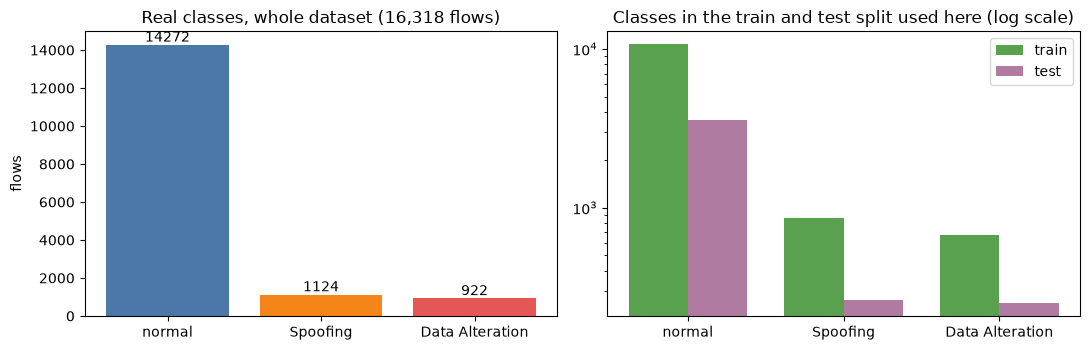

In [6]:
print("dataset shape:", raw.shape)
print("all columns:", list(raw.columns))
print("\nmodel features (%d):" % len(D["names"]), D["names"])
print("\nidentifier columns dropped:", ID_COLS)
print("\noriginal label values (Label):", raw[LABEL].value_counts().to_dict(), "(0 = normal, 1 = attack)")
print("attack categories:", raw[CATEGORY].value_counts().to_dict())
print("\ntrain / test sizes:", len(D["ytr"]), "/", len(D["yte"]), "| attack share train %.3f, test %.3f" % (D["ytr"].mean(), D["yte"].mean()))

CAT_ORDER = ["normal", "Spoofing", "Data Alteration"]
CAT_COLOR = {"normal": "#4c78a8", "Spoofing": "#f58518", "Data Alteration": "#e45756"}
cat_tr = raw[CATEGORY].to_numpy()[D["tr"]]; cat_te = raw[CATEGORY].to_numpy()[D["te"]]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
counts = raw[CATEGORY].value_counts().reindex(CAT_ORDER)
ax[0].bar(counts.index, counts.values, color=[CAT_COLOR[c] for c in counts.index])
for i, v in enumerate(counts.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Real classes, whole dataset (16,318 flows)"); ax[0].set_ylabel("flows")
w = 0.38; xs = np.arange(3)
ax[1].bar(xs - w/2, [np.sum(cat_tr == c) for c in CAT_ORDER], w, label="train", color="#59a14f")
ax[1].bar(xs + w/2, [np.sum(cat_te == c) for c in CAT_ORDER], w, label="test", color="#b07aa1")
ax[1].set_xticks(xs); ax[1].set_xticklabels(CAT_ORDER); ax[1].set_yscale("log"); ax[1].legend()
ax[1].set_title("Classes in the train and test split used here (log scale)")
plt.tight_layout(); plt.show()

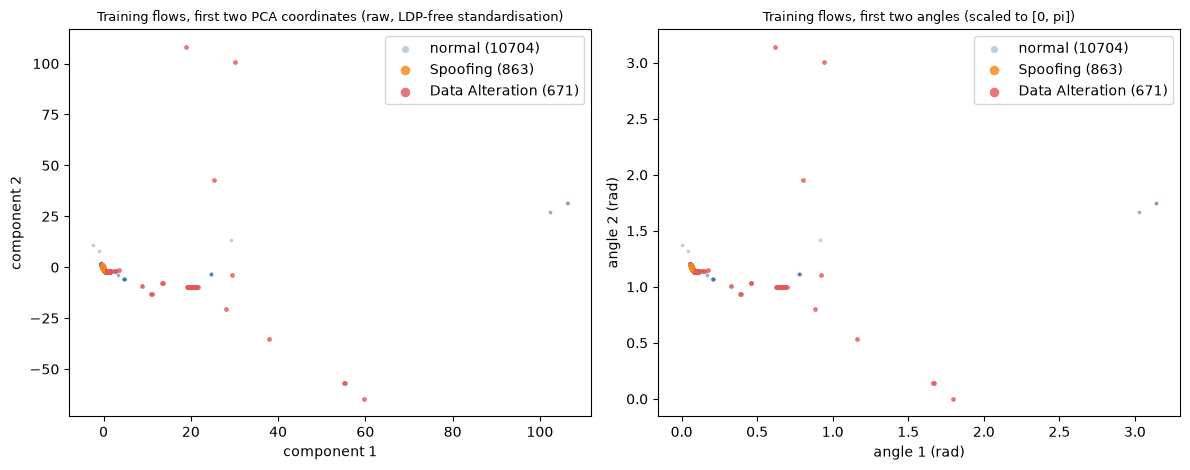

The attack flows overlap the normal cloud in the first two components: the 30 features alone separate them only partly.


In [7]:
# 2-D scatter of REAL training flows, coloured by the ground-truth attack family
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for panel, (M, ttl, lim) in enumerate([(D["Ptr"], "Training flows, first two PCA coordinates (raw, LDP-free standardisation)", None),
                                       (D["Atr"], "Training flows, first two angles (scaled to [0, pi])", (0, np.pi))]):
    for c in CAT_ORDER:
        m = cat_tr == c
        ax[panel].scatter(M[m, 0], M[m, 1], s=7 if c == "normal" else 12, alpha=0.35 if c == "normal" else 0.8,
                          color=CAT_COLOR[c], label=f"{c} ({m.sum()})", linewidths=0)
    ax[panel].set_xlabel("component 1" if panel == 0 else "angle 1 (rad)"); ax[panel].set_ylabel("component 2" if panel == 0 else "angle 2 (rad)")
    ax[panel].set_title(ttl, fontsize=9); ax[panel].legend(markerscale=2)
plt.tight_layout(); plt.show()
print("The attack flows overlap the normal cloud in the first two components: the 30 features alone separate them only partly.")

## 3. The quantum kernel on 6 qubits

The quantum feature map is the ZZ feature map: Hadamards on all qubits, a phase `P(2 x_i)` on every qubit and a
two-qubit `ZZ` phase `2 (pi - x_i)(pi - x_j)` on every neighbouring pair, repeated twice. The kernel of two records is the
fidelity `k(x', x'') = |<phi(x')|phi(x'')>|^2 = |<0|U(x'')^dagger U(x')|0>|^2` (paper Eq. 8).

Simulating one circuit per kernel entry would be slow, so the exact statevector of every record is computed once with a
vectorised numpy implementation of the same circuit (all phase gates are diagonal; the Hadamard layers are a fixed 64 x 64
matrix), and every kernel entry is then a 64-term inner product. The cell below **asserts** that this numpy statevector
equals Qiskit's `Statevector` of the circuit built from `zz_feature_map`, and that the resulting kernel matrix equals
Qiskit's `FidelityStatevectorKernel`, so nothing is approximated.

In [8]:
NQ = N_QUBITS
BITS = ((np.arange(2 ** NQ)[:, None] >> np.arange(NQ)[None, :]) & 1).astype(float)          # (64, 6), little-endian like Qiskit
_H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
HN = np.array([[1.0]])
for _ in range(NQ): HN = np.kron(_H1, HN)
PAIRS = [(i, i + 1) for i in range(NQ - 1)]                                                   # linear entanglement
PARITY = np.stack([(BITS[:, i] != BITS[:, j]).astype(float) for i, j in PAIRS], 1)            # (64, 5)

def states(A, reps=FM_REPS):
    # exact statevectors of zz_feature_map(NQ, reps, "linear") for angle rows A (B, NQ)
    A = np.atleast_2d(A)
    phase = (2 * A) @ BITS.T + np.stack([2 * (np.pi - A[:, i]) * (np.pi - A[:, j]) for i, j in PAIRS], 1) @ PARITY.T
    Dg = np.exp(1j * phase)
    psi = np.tile(HN[:, 0], (len(A), 1)).astype(complex) * Dg
    for _ in range(reps - 1):
        psi = (psi @ HN.T) * Dg
    return psi

KERNEL_ENTRIES = 0           # counts quantum kernel entries (circuit pairs) used, for the cost discussion (Table III)
def kern(Sa, Sb):
    global KERNEL_ENTRIES
    KERNEL_ENTRIES += Sa.shape[0] * Sb.shape[0]
    return np.abs(Sa @ Sb.conj().T) ** 2

# ---- equivalence checks against Qiskit ----
FM = zz_feature_map(NQ, reps=FM_REPS, entanglement=ENTANGLEMENT)
chk = np.random.default_rng(0).uniform(0, np.pi, (12, NQ))
sv_q = np.array([Statevector(FM.assign_parameters(p)).data for p in chk])
assert np.allclose(sv_q, states(chk), atol=1e-12), "numpy statevectors differ from Qiskit"
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
K_q = FidelityStatevectorKernel(feature_map=FM).evaluate(chk)
K_n = kern(states(chk), states(chk))
assert np.allclose(K_q, K_n, atol=1e-10), "kernel differs from FidelityStatevectorKernel"
print("numpy statevectors == Qiskit Statevector (max abs diff %.1e); kernel == FidelityStatevectorKernel (max abs diff %.1e)"
      % (np.abs(sv_q - states(chk)).max(), np.abs(K_q - K_n).max()))
KERNEL_ENTRIES = 0

numpy statevectors == Qiskit Statevector (max abs diff 2.3e-15); kernel == FidelityStatevectorKernel (max abs diff 3.8e-15)


## Quantum Circuit Architecture

The quantum part of the QRF is the **kernel circuit**: the feature map `U(x')` followed by the inverse feature map
`U(x'')^dagger`, measured in the computational basis; the probability of the all-zero outcome is the kernel entry (Eq. 8).
Nothing in the quantum circuit is trained: the trainable parts of the QRF (landmarks, SVM weights, tree structure) are
classical. Assumptions where the paper is silent: ZZ feature map, 2 repetitions, linear entanglement, one principal
component per qubit (6 qubits inferred from `2^6` in Table III), angles in [0, pi] times a bandwidth.

First the feature map `U(x)` for one real training record, transpiled to `h, p, cx`; then the full kernel circuit of two
real training records of different classes, with its measurement. The last cell asserts that the all-zero probability of
this very circuit equals the kernel entry used by the forest.

record A (normal): [0.071 1.177 1.162 0.    1.553 2.42 ]
record B (attack): [0.097 1.137 1.1   1.446 1.734 1.874]


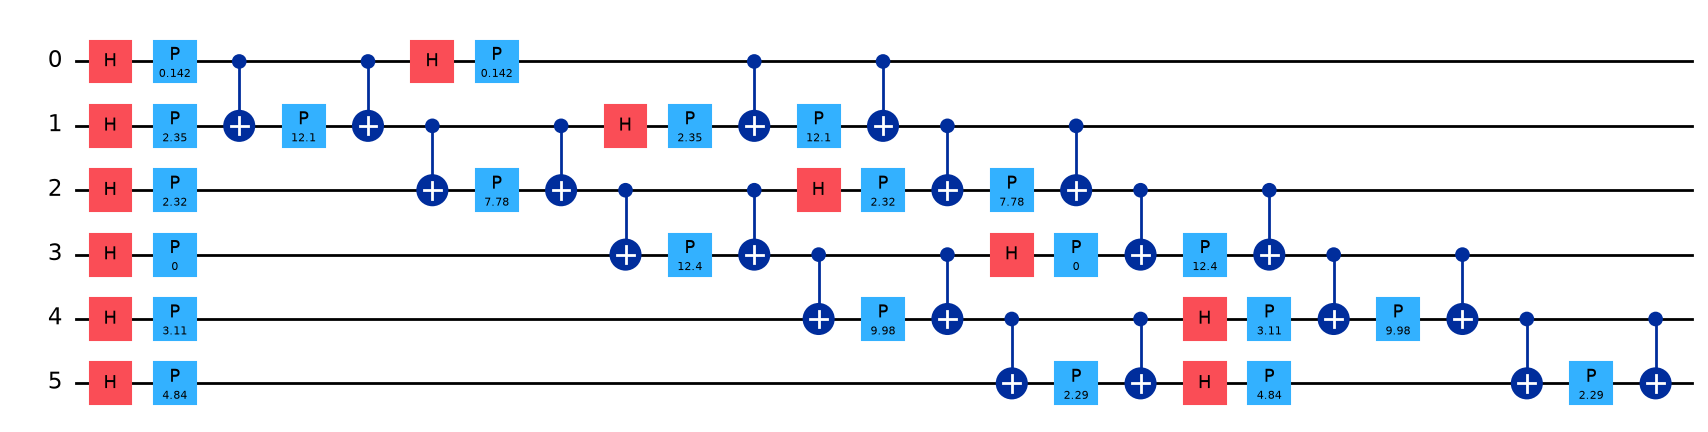

U(x) for record A: qubits = 6, depth = 25, gates = {'p': 22, 'cx': 20, 'h': 12}
abstract feature map: data parameters = 6 (one per qubit), trainable quantum parameters = 0


In [9]:
i_norm = int(np.where(D["ytr"] == 0)[0][0]); i_att = int(np.where(D["ytr"] == 1)[0][0])
xa, xb = D["Atr"][i_norm], D["Atr"][i_att]
print("record A (normal):", np.round(xa, 3)); print("record B (attack):", np.round(xb, 3))

BASIS = ["h", "p", "cx"]
U_a = transpile(FM.assign_parameters(xa), basis_gates=BASIS, optimization_level=0)
display(U_a.draw("mpl", fold=45, style="iqp"))
print(f"U(x) for record A: qubits = {U_a.num_qubits}, depth = {U_a.depth()}, gates = {dict(U_a.count_ops())}")
print(f"abstract feature map: data parameters = {FM.num_parameters} (one per qubit), trainable quantum parameters = 0")

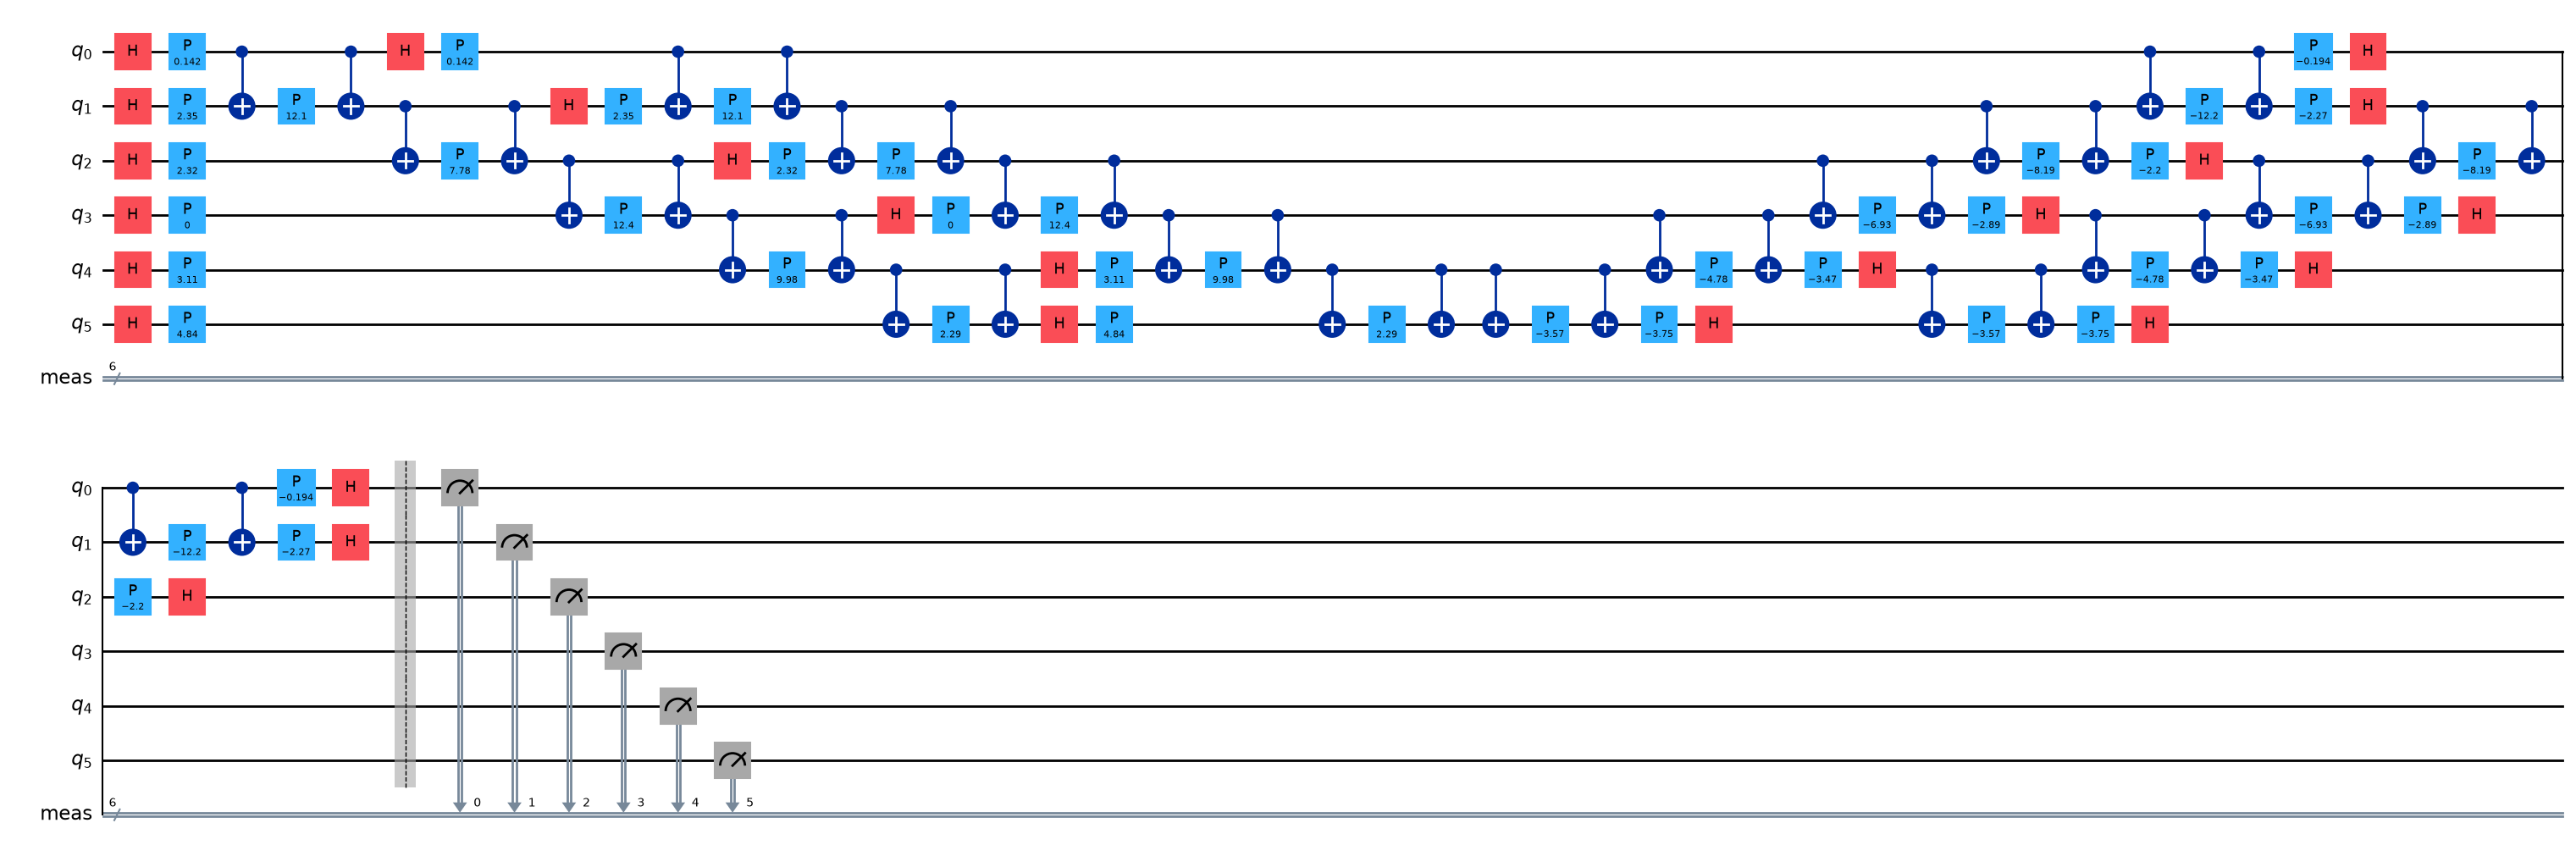

kernel circuit: qubits = 6, depth = 50 (+ measurement), gates = {'p': 44, 'cx': 40, 'h': 24}, trainable parameters = 0
P(000000) of the drawn circuit = 0.018308  ==  kernel entry used by the forest = 0.018308
Architectures compared: one (all trees and all nodes use this kernel circuit; they differ only in which records/landmarks are fed in).


In [10]:
from qiskit import QuantumCircuit
kc = QuantumCircuit(NQ)
kc.compose(FM.assign_parameters(xa), inplace=True)            # U(x')
kc.compose(FM.assign_parameters(xb).inverse(), inplace=True)  # U(x'')^dagger
kc_t = transpile(kc, basis_gates=BASIS, optimization_level=0)
kc_m = kc_t.copy(); kc_m.measure_all()
display(kc_m.draw("mpl", fold=45, style="iqp"))
print(f"kernel circuit: qubits = {kc_m.num_qubits}, depth = {kc_t.depth()} (+ measurement), gates = {dict(kc_t.count_ops())}, trainable parameters = 0")

p0 = Statevector(kc_t).probabilities_dict().get("0" * NQ, 0.0)
k_forest = float(kern(states(xa), states(xb))[0, 0]); KERNEL_ENTRIES = 0
assert abs(p0 - k_forest) < 1e-10
print(f"P(000000) of the drawn circuit = {p0:.6f}  ==  kernel entry used by the forest = {k_forest:.6f}")
print("Architectures compared: one (all trees and all nodes use this kernel circuit; they differ only in which records/landmarks are fed in).")

## 4. The kernel-based quantum random forest

Implemented from the paper's Section III-B and from Srikumar et al.:

* **Quantum decision tree (QDT).** At a node holding a set of records, `SPLIT_TRIES` times: draw `L = 5` random landmark
  records from the node; compute the quantum kernel between all node records and the landmarks (`n x 5` entries) and between
  the landmarks (`5 x 5`); the **Nystroem features** are `K_nL K_LL^{-1/2}`; train a linear SVM on them with the node's
  class labels; the sign of its decision function sends a record left or right. The candidate split with the highest
  **information gain** (Eq. 5, entropy over the class distribution) is kept. A node becomes a leaf at depth 4, when it is
  pure, or when it holds fewer records than landmarks. A leaf stores the class distribution `Pr(c | leaf)`.
* **Forest.** Each of the 3 trees is trained on a bootstrap sample of the training records; the prediction for a new record
  is the class with the highest mean leaf probability over the trees (Eq. 4).
* At prediction time a record's kernel is evaluated against the landmarks of each node it passes through.

In [11]:
def entropy(y):
    if len(y) == 0: return 0.0
    p = np.bincount(y, minlength=2) / len(y); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

class QDT:
    def __init__(self, S, y, rng, depth=MAX_DEPTH, L=N_LANDMARKS, tries=SPLIT_TRIES, C=SVM_C):
        self.S, self.y, self.rng, self.depth, self.L, self.tries, self.C = S, y, rng, depth, L, tries, C
        self.n_splits = 0
    def fit(self, rows):
        self.root = self._grow(rows, 0); return self
    def _grow(self, rows, d):
        yy = self.y[rows]; counts = np.bincount(yy, minlength=2)
        leaf = {"leaf": True, "p": counts / counts.sum()}
        uniq = np.unique(rows)
        if d >= self.depth or counts.min() == 0 or len(uniq) < max(self.L, 2): return leaf
        best = None
        for _ in range(self.tries):
            lm = self.rng.choice(uniq, self.L, replace=False)                 # landmark records (Nystroem)
            Sl = self.S[lm]
            w, V = np.linalg.eigh(kern(Sl, Sl)); w = np.clip(w, 1e-8, None)
            Wm = V @ np.diag(w ** -0.5) @ V.T                                   # K_LL^{-1/2}
            F = kern(self.S[rows], Sl) @ Wm                                     # Nystroem features in the quantum feature space
            svm = LinearSVC(C=self.C, class_weight=CLASS_WEIGHT, max_iter=5000, random_state=0).fit(F, yy)
            side = svm.decision_function(F) > 0
            if side.all() or (~side).all(): continue
            ig = entropy(yy) - side.mean() * entropy(yy[side]) - (~side).mean() * entropy(yy[~side])   # Eq. 5
            if best is None or ig > best[0]: best = (ig, Sl, Wm, svm.coef_[0].copy(), float(svm.intercept_[0]), side)
        if best is None: return leaf
        ig, Sl, Wm, wv, b, side = best
        self.n_splits += 1
        return {"leaf": False, "Sl": Sl, "Wm": Wm, "w": wv, "b": b,
                "l": self._grow(rows[side], d + 1), "r": self._grow(rows[~side], d + 1)}
    def proba(self, S):
        out = np.zeros((len(S), 2)); self._route(self.root, np.arange(len(S)), S, out); return out
    def _route(self, node, ii, S, out):
        if len(ii) == 0: return
        if node["leaf"]: out[ii] = node["p"]; return
        side = (kern(S[ii], node["Sl"]) @ node["Wm"]) @ node["w"] + node["b"] > 0
        self._route(node["l"], ii[side], S, out); self._route(node["r"], ii[~side], S, out)

class QRF:
    def __init__(self, T=N_TREES, seed=SEED, **kw): self.T, self.seed, self.kw = T, seed, kw
    def fit(self, S, y, rows=None):
        rows = np.arange(len(y)) if rows is None else np.asarray(rows)
        r = np.random.default_rng(self.seed); self.trees = []
        for _ in range(self.T):
            boot = r.choice(rows, len(rows), replace=True)                       # bagging
            self.trees.append(QDT(S, y, r, **self.kw).fit(boot))
        return self
    def proba(self, S): return np.mean([t.proba(S) for t in self.trees], axis=0)       # Eq. 4: mean over trees
    def predict(self, S): return self.proba(S).argmax(1)
    @property
    def n_splits(self): return sum(t.n_splits for t in self.trees)

def metrics(y, p):
    return dict(acc=accuracy_score(y, p) * 100,
                prec_att=precision_score(y, p, pos_label=1, zero_division=0) * 100, rec_att=recall_score(y, p, pos_label=1, zero_division=0) * 100,
                f1_att=f1_score(y, p, pos_label=1, zero_division=0) * 100,
                prec_norm=precision_score(y, p, pos_label=0, zero_division=0) * 100, rec_norm=recall_score(y, p, pos_label=0, zero_division=0) * 100,
                f1_norm=f1_score(y, p, pos_label=0, zero_division=0) * 100,
                mcc=matthews_corrcoef(y, p))

# quick smoke test on the seed-42 split
t0 = time.time()
_S = states(D["Atr"]); q = QRF(seed=SEED).fit(_S, D["ytr"]); _p = q.predict(states(D["Ate"]))
print(f"QRF fitted on {len(D['ytr'])} flows in {time.time() - t0:.1f} s; {q.n_splits} split nodes; test accuracy {accuracy_score(D['yte'], _p):.4f}")

QRF fitted on 12238 flows in 11.4 s; 45 split nodes; test accuracy 0.9235


## 5. Choosing the kernel bandwidth on a validation split

The paper does not say how its angles were scaled. The kernel's bandwidth (a multiplier of the [0, pi] angles) strongly
changes how "wide" the quantum kernel is: too large and all records look orthogonal, too small and all look alike. We pick it
from `BW_GRID` on a stratified validation part (25 %) of the **training** data only, maximising the MCC (accuracy is a poor
criterion with 87.5 % normal records); the test split is not touched.

In [12]:
def pick_bandwidth(seed=SEED):
    d = preprocess(seed)
    itr, iva = train_test_split(np.arange(len(d["ytr"])), test_size=VAL_FRACTION, stratify=d["ytr"], random_state=seed)
    rows = []
    for bw in BW_GRID:
        S = states(d["Atr"] * bw)
        m = QRF(seed=seed).fit(S, d["ytr"], rows=itr)
        pv = m.predict(S[iva])
        rows.append(dict(bandwidth=bw, val_acc=accuracy_score(d["ytr"][iva], pv) * 100, val_mcc=matthews_corrcoef(d["ytr"][iva], pv)))
    t = pd.DataFrame(rows); return t, float(t.loc[t["val_mcc"].idxmax(), "bandwidth"])

bw_table, BW = pick_bandwidth()
display(bw_table.round(4)); print("chosen bandwidth:", BW)

,bandwidth,val_acc,val_mcc
0,0.10,92.8105,0.6262
1,0.25,92.7451,0.6226
2,0.50,92.6471,0.6163
3,1.00,92.2876,0.5928


chosen bandwidth: 0.1


## 6. Main experiment: QRF with and without the privacy layer

For each seed the data are split again, the pipeline is refitted on that seed's training part and the QRF is trained and
tested. "Without LDP" uses the ordinary standard scaler; "with LDP" uses Algorithm 1 with epsilon = 1. Accuracy, precision,
recall and F1 are given with the **attack** class positive (the project's convention) and with the **normal** class
positive (see section 7 for why); MCC does not depend on that choice. Do not be surprised that the two privacy settings give the same numbers: section 8 shows why. The classical baselines get exactly the same six
[0, pi] PCA values per record.

In [13]:
def run_one(seed, eps, bw=BW, with_ids=False, T=N_TREES, L=N_LANDMARKS, depth=MAX_DEPTH, tries=SPLIT_TRIES, keep_pred=False):
    global KERNEL_ENTRIES
    d = preprocess(seed, eps, with_ids)
    KERNEL_ENTRIES = 0
    t0 = time.time()
    S_tr = states(d["Atr"] * bw)
    q = QRF(T=T, seed=seed, L=L, depth=depth, tries=tries).fit(S_tr, d["ytr"])
    t_fit = time.time() - t0
    t0 = time.time(); proba = q.proba(states(d["Ate"] * bw)); t_pred = time.time() - t0
    pred = proba.argmax(1)
    row = dict(seed=seed, eps="none" if eps is None else str(eps), with_ids=with_ids, T=T, L=L, depth=depth, tries=tries,
               fit_s=t_fit, pred_s=t_pred, kernel_entries=KERNEL_ENTRIES, **metrics(d["yte"], pred))
    return (row, d, q, proba) if keep_pred else row

main_rows, keep = [], {}
for eps in [None, EPSILON]:
    for s in SEEDS:
        out = run_one(s, eps, keep_pred=True); main_rows.append(out[0])
        if s == SEEDS[0]: keep[eps] = out
main = pd.DataFrame(main_rows)
cols = ["acc", "prec_att", "rec_att", "f1_att", "prec_norm", "rec_norm", "f1_norm", "mcc", "fit_s"]
agg = main.groupby("eps")[cols].agg(["mean", "std"]).round(3)
print("QRF, per-seed results:"); display(main.round(3))
print("\nmean and std over seeds:"); display(agg)

QRF, per-seed results:


,seed,eps,with_ids,T,L,depth,tries,fit_s,pred_s,kernel_entries,acc,prec_att,rec_att,f1_att,prec_norm,rec_norm,f1_norm,mcc
0,42,none,False,3,5,4,5,7.334,0.266,3921825,92.843,89.568,48.633,63.038,93.083,99.187,96.038,0.629
1,43,none,False,3,5,4,5,6.407,0.358,3921825,91.961,93.396,38.672,54.696,91.882,99.608,95.589,0.571
2,44,none,False,3,5,4,5,6.611,0.205,3921825,92.010,84.444,44.531,58.312,92.546,98.823,95.581,0.578
3,45,none,False,3,5,4,5,9.851,0.319,3921825,92.794,94.309,45.312,61.214,92.697,99.608,96.028,0.625
4,46,none,False,3,5,4,5,6.118,0.277,3921825,92.157,90.336,41.992,57.333,92.270,99.355,95.682,0.584
5,42,1.0,False,3,5,4,5,6.447,0.384,3921825,92.843,89.568,48.633,63.038,93.083,99.187,96.038,0.629
6,43,1.0,False,3,5,4,5,7.389,0.321,3921825,91.961,93.396,38.672,54.696,91.882,99.608,95.589,0.571
7,44,1.0,False,3,5,4,5,6.702,0.269,3921825,92.010,84.444,44.531,58.312,92.546,98.823,95.581,0.578
8,45,1.0,False,3,5,4,5,10.429,0.504,3921825,92.794,94.309,45.312,61.214,92.697,99.608,96.028,0.625
9,46,1.0,False,3,5,4,5,7.266,0.333,3921825,92.157,90.336,41.992,57.333,92.270,99.355,95.682,0.584



mean and std over seeds:


acc        prec_att        rec_att         f1_att        prec_norm        rec_norm        f1_norm           mcc         fit_s       
        mean    std     mean    std    mean    std    mean    std      mean    std     mean    std    mean    std   mean    std   mean    std
eps                                                                                                                                          
1.0   92.353  0.432   90.411  3.887  43.828  3.733  58.919  3.277    92.495  0.451   99.316  0.328  95.784  0.231  0.597  0.027  7.647  1.603
none  92.353  0.432   90.411  3.887  43.828  3.733  58.919  3.277    92.495  0.451   99.316  0.328  95.784  0.231  0.597  0.027  7.264  1.514

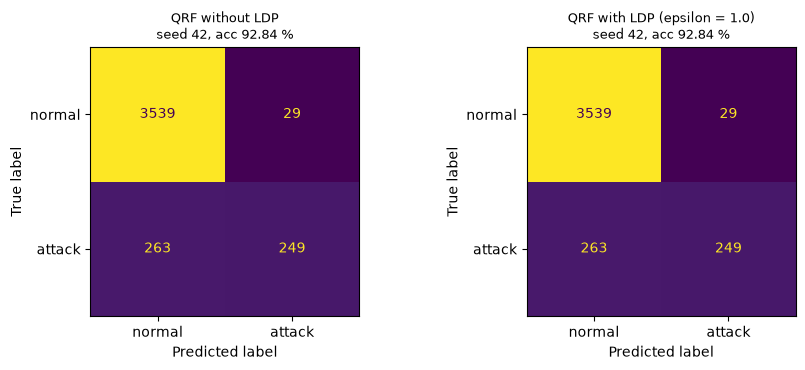

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, eps, name in zip(ax, [None, EPSILON], ["QRF without LDP", f"QRF with LDP (epsilon = {EPSILON})"]):
    d = keep[eps][1]; pred = keep[eps][3].argmax(1)
    cm = confusion_matrix(d["yte"], pred, labels=[0, 1])        # rows true, columns predicted; attack = positive class (label 1)
    ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=a, colorbar=False, values_format="d")
    a.set_title(f"{name}\nseed {SEEDS[0]}, acc {accuracy_score(d['yte'], pred) * 100:.2f} %", fontsize=9)
plt.tight_layout(); plt.show()

### Classical baselines on the same inputs

Random forest (100 trees; and 3 trees of depth 4, the same size as the QRF), RBF-SVM, logistic regression and Gaussian naive
Bayes, trained on the identical six [0, pi] PCA values; plus a 100-tree random forest on all 30 standardised features. LR, NB
and RF are the comparators of the paper's Table IV (which is on the ICU data we do not have).

In [15]:
# CHOICE: the paper gives no SVM settings; C of the RBF-SVM is picked on the same inner validation split as the bandwidth (MCC)
_d0 = preprocess(SEED); _itr, _iva = train_test_split(np.arange(len(_d0["ytr"])), test_size=VAL_FRACTION, stratify=_d0["ytr"], random_state=SEED)
svc_val = pd.DataFrame([dict(C=C_, val_mcc=matthews_corrcoef(_d0["ytr"][_iva], SVC(C=C_, gamma="scale").fit(_d0["Atr"][_itr], _d0["ytr"][_itr]).predict(_d0["Atr"][_iva])))
                        for C_ in [1.0, 10.0, 100.0]])
SVC_C = float(svc_val.loc[svc_val["val_mcc"].idxmax(), "C"]); display(svc_val.round(4)); print("chosen C for the RBF-SVM:", SVC_C)

def baselines(seed, eps):
    d = preprocess(seed, eps)
    models = {"RF-100 (6 PCA)": RandomForestClassifier(100, random_state=seed, n_jobs=2),
              "RF-3 depth 4 (6 PCA)": RandomForestClassifier(3, max_depth=4, random_state=seed),
              "SVC rbf (6 PCA)": SVC(kernel="rbf", C=SVC_C, gamma="scale"),
              "LogReg (6 PCA)": LogisticRegression(max_iter=2000),
              "GaussianNB (6 PCA)": GaussianNB()}
    rows = []
    for name, m in models.items():
        t0 = time.time(); m.fit(d["Atr"], d["ytr"]); p = m.predict(d["Ate"])
        rows.append(dict(seed=seed, eps="none" if eps is None else str(eps), model=name, time_s=time.time() - t0, **metrics(d["yte"], p)))
    m = RandomForestClassifier(100, random_state=seed, n_jobs=2); t0 = time.time(); m.fit(d["Ztr"], d["ytr"]); p = m.predict(d["Zte"])
    rows.append(dict(seed=seed, eps="none" if eps is None else str(eps), model="RF-100 (all 30 features)", time_s=time.time() - t0, **metrics(d["yte"], p)))
    return rows

base = pd.DataFrame([r for eps in [None, EPSILON] for s in SEEDS for r in baselines(s, eps)])
bt = base.groupby(["eps", "model"])[["acc", "f1_att", "f1_norm", "mcc", "time_s"]].agg(["mean", "std"]).round(3)
qrf_row = main.groupby("eps")[["acc", "f1_att", "f1_norm", "mcc", "fit_s"]].agg(["mean", "std"]).round(3)
display(bt)
print("QRF (for comparison):"); display(qrf_row)
print("Majority-class rate of the test split (always predicting 'normal'): %.2f %%" % ((1 - D["yte"].mean()) * 100))

,C,val_mcc
0,1.0,0.1339
1,10.0,0.6368
2,100.0,0.6368


chosen C for the RBF-SVM: 10.0


acc         f1_att         f1_norm           mcc         time_s       
                                 mean    std    mean     std    mean    std   mean    std    mean    std
eps  model                                                                                              
1.0  GaussianNB (6 PCA)        90.652  1.616  48.525  17.450  94.845  0.843  0.484  0.142   0.021  0.004
     LogReg (6 PCA)            89.353  1.127  28.042  11.937  94.249  0.579  0.355  0.103   0.236  0.060
     RF-100 (6 PCA)            92.873  0.320  62.235   2.417  96.065  0.169  0.630  0.020   5.817  1.167
     RF-100 (all 30 features)  93.716  0.309  67.401   2.116  96.523  0.166  0.681  0.018   6.007  0.623
     RF-3 depth 4 (6 PCA)      92.941  0.309  61.473   2.532  96.114  0.162  0.635  0.019   0.246  0.134
     SVC rbf (6 PCA)           92.804  0.290  61.141   2.430  96.035  0.151  0.626  0.018  11.249  1.186
none GaussianNB (6 PCA)        90.652  1.616  48.525  17.450  94.845  0.843  0.484  0.142   0.016  0.003
     LogReg (6 PCA)            89.353  1.127  27.987  11.987  94.250  0.578  0.355  0.103   0.216  0.047
     RF-100 (6 PCA)            92.873  0.320  62.235   2.417  96.065  0.169  0.630  0.020   4.763  0.642
     RF-100 (all 30 features)  93.711  0.283  67.335   1.996  96.520  0.151  0.681  0.016   4.641  0.514
     RF-3 depth 4 (6 PCA)      92.941  0.309  61.473   2.532  96.114  0.162  0.635  0.019   0.116  0.027
     SVC rbf (6 PCA)           92.804  0.290  61.141   2.430  96.035  0.151  0.626  0.018   9.788  0.606

QRF (for comparison):


acc         f1_att        f1_norm           mcc         fit_s       
        mean    std    mean    std    mean    std   mean    std   mean    std
eps                                                                          
1.0   92.353  0.432  58.919  3.277  95.784  0.231  0.597  0.027  7.647  1.603
none  92.353  0.432  58.919  3.277  95.784  0.231  0.597  0.027  7.264  1.514

Majority-class rate of the test split (always predicting 'normal'): 87.45 %


## 7. Why the paper's 99.9 % is not reachable from the 30 features: the identifier shortcut

The paper reports 99.93 % accuracy on WUSTL-EHMS-2020, but a 100-tree random forest on all 30 traffic and vital-sign
features reaches only about 94 % here, and the majority-class rate is 87.5 %. So something else is going on. Two checks.

**(a) Which positive class does the paper use?** The paper's WUSTL numbers are precision 99.92 %, recall 100 %, accuracy
99.93 %. With the attack class positive and recall 100 % there would be no false negatives, and a precision of 99.92 %
would mean about 0.0008 x 512 = 0.4 false positives among the 512 test attacks, so accuracy would be about 99.99 %, not
99.93 %. With the **normal** class positive (3,568 test records), recall 100 % means every normal flow is kept and
precision 99.92 % means about 3 attacks were let through: accuracy = 1 - 3/4,080 = 99.93 %. The numbers are therefore
consistent only with the normal class as positive (or with a weighted average), which is why this notebook reports both.

**(b) What could give 99.9 %?** The table has a column `SrcMac` that holds the MAC address of the sender. All normal
flows come from one device and every attack flow from the attacker's device, so the column is a perfect label proxy.
Below we count the cross-tabulation and train the same random forest with the identifier columns added back (`Sport`,
`Flgs`, `SrcMac`; 33 features).

In [16]:
print("SrcMac versus attack category (counts):")
display(pd.crosstab(raw["SrcMac"], raw[CATEGORY]))
print("Flgs versus attack category (counts):")
display(pd.crosstab(raw["Flgs"].str.strip(), raw[CATEGORY]))

# (a) the arithmetic of the paper's own numbers
n_te, n_att, n_norm = 4080, 512, 3568
fp_att = n_att * 0.0008        # attack positive, recall 100 %: false positives implied by precision 99.92 %
print("\nattack-positive reading: implied accuracy = %.3f %% (paper: 99.93 %%)" % ((1 - fp_att / n_te) * 100))
fn_att = n_norm * 0.0008                                       # normal positive, recall 100 %: attacks let through implied by precision 99.92 %
print("normal-positive reading: implied accuracy = %.3f %% (paper: 99.93 %%)" % ((1 - fn_att / n_te) * 100))

# (b) random forest with and without the identifier columns, same split, same seed
res = []
for with_ids in [False, True]:
    Xtr, Xte, ytr, yte, names, tr, te = split_features(SEED, with_ids)
    m = RandomForestClassifier(100, random_state=SEED, n_jobs=2).fit(Xtr, ytr); p = m.predict(Xte)
    imp = pd.Series(m.feature_importances_, names).sort_values(ascending=False)
    res.append(dict(features=len(names), with_identifiers=with_ids, rf_accuracy=accuracy_score(yte, p) * 100, top_feature=imp.index[0],
                    top_importance=imp.iloc[0]))
display(pd.DataFrame(res).round(3))

SrcMac versus attack category (counts):


Attack Category,Data Alteration,Spoofing,normal
SrcMac,,,
84:3a:4b:0f:5b:94,0,0,14272
d8:9e:f3:95:02:75,922,1124,0


Flgs versus attack category (counts):


Attack Category,Data Alteration,Spoofing,normal
Flgs,,,
M,921,1,2
M *,0,0,7
M d,1,0,2
MR,0,1,0
e,0,984,14253
e s,0,0,8
eR,0,138,0



attack-positive reading: implied accuracy = 99.990 % (paper: 99.93 %)
normal-positive reading: implied accuracy = 99.930 % (paper: 99.93 %)


,features,with_identifiers,rf_accuracy,top_feature,top_importance
0,30,False,94.314,DstJitter,0.126
1,33,True,100.000,SrcMac,0.602


In [17]:
# The full paper pipeline (scaler -> PCA(6) -> QRF) also with the identifier columns added back: does it reach 99.9 % ?
id_rows = []
for eps in [None, EPSILON]:
    for s in SEEDS:
        id_rows.append(run_one(s, eps, with_ids=True))
id_df = pd.DataFrame(id_rows)
display(id_df.groupby("eps")[["acc", "prec_norm", "rec_norm", "f1_norm", "f1_att", "mcc"]].agg(["mean", "std"]).round(3))

acc        prec_norm       rec_norm        f1_norm         f1_att          mcc       
        mean    std      mean   std     mean    std    mean    std    mean   std   mean    std
eps                                                                                           
1.0   95.907  1.762    95.898  1.89   99.613  0.163  97.712  0.968  80.488  9.53  0.799  0.091
none  95.907  1.762    95.898  1.89   99.613  0.163  97.712  0.968  80.488  9.53  0.799  0.091

## 8. Re-drawing the paper's figures

**Fig. 3** shows the distribution of some WUSTL-EHMS-2020 features before and after the LDP scaler. **Fig. 5** shows the
MCC with and without LDP. (Fig. 4 is the ICU data and cannot be drawn.)

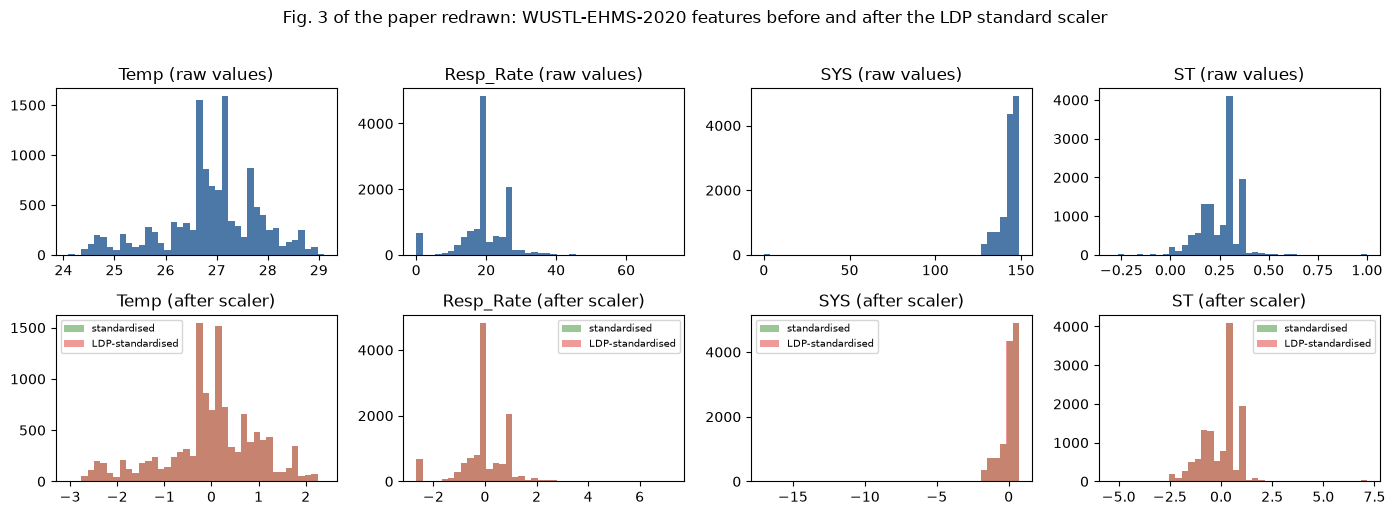

Largest shift of a feature mean caused by the Laplace noise (in standard deviations): 0.0160
Median shift: 0.00203. The noise is tiny because the scale b = ((max - min) / n) / epsilon is divided by n = 12238.

max |angle(with LDP) - angle(without LDP)| over all training and test records: train 3.55e-14, test 3.44e-14
so the QRF receives (numerically) the same inputs with and without the paper's LDP layer; the same 'privacy' is removed by PCA centring.


In [18]:
d_plain, d_ldp = keep[None][1], keep[EPSILON][1]
feats = ["Temp", "Resp_Rate", "SYS", "ST"]
fig, ax = plt.subplots(2, 4, figsize=(14, 5))
for j, f in enumerate(feats):
    k = d_plain["names"].index(f)
    ax[0, j].hist(d_plain["Xtr"][:, k], bins=40, color="#4c78a8"); ax[0, j].set_title(f + " (raw values)")
    ax[1, j].hist(d_plain["Ztr"][:, k], bins=40, alpha=0.6, color="#59a14f", label="standardised")
    ax[1, j].hist(d_ldp["Ztr"][:, k], bins=40, alpha=0.6, color="#e45756", label="LDP-standardised")
    ax[1, j].set_title(f + " (after scaler)"); ax[1, j].legend(fontsize=7)
fig.suptitle("Fig. 3 of the paper redrawn: WUSTL-EHMS-2020 features before and after the LDP standard scaler", y=1.02)
plt.tight_layout(); plt.show()
shift = np.abs(d_ldp["Ztr"].mean(0) - d_plain["Ztr"].mean(0))
print("Largest shift of a feature mean caused by the Laplace noise (in standard deviations): %.4f" % shift.max())
print("Median shift: %.5f. The noise is tiny because the scale b = ((max - min) / n) / epsilon is divided by n = %d." % (np.median(shift), len(d_plain["ytr"])))

# Why the table in section 6 shows identical numbers with and without LDP: the noisy mean is a constant translation of every
# record (train and test alike); PCA subtracts the training mean and the min-max scaler removes any remaining offset.
print("\nmax |angle(with LDP) - angle(without LDP)| over all training and test records: train %.2e, test %.2e"
      % (np.abs(d_plain["Atr"] - d_ldp["Atr"]).max(), np.abs(d_plain["Ate"] - d_ldp["Ate"]).max()))
print("so the QRF receives (numerically) the same inputs with and without the paper's LDP layer; the same 'privacy' is removed by PCA centring.")

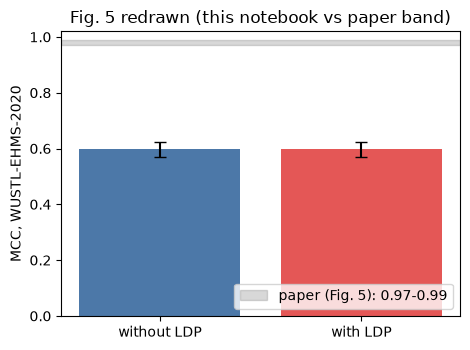

In [19]:
mcc_t = main.groupby("eps")["mcc"].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(4.8, 3.6))
ax.bar(["without LDP", "with LDP"], [mcc_t.loc["none", "mean"], mcc_t.loc[str(EPSILON), "mean"]], yerr=[mcc_t.loc["none", "std"], mcc_t.loc[str(EPSILON), "std"]],
       color=["#4c78a8", "#e45756"], capsize=4)
ax.axhspan(0.97, 0.99, color="gray", alpha=0.3, label="paper (Fig. 5): 0.97-0.99")
ax.set_ylim(0, 1.02); ax.set_ylabel("MCC, WUSTL-EHMS-2020"); ax.legend(loc="lower right"); ax.set_title("Fig. 5 redrawn (this notebook vs paper band)")
plt.tight_layout(); plt.show()

## 9. Time and memory complexity (Table III)

The paper evaluates formulas, not measurements. The cell recomputes its arithmetic for the WUSTL numbers (n = 12,238,
f = 30, L = 5, 2^6 for the simulated qubits, 2,024 as the paper's `spke` factor) and then measures what this notebook
actually spends: the number of quantum-kernel entries and the peak memory of one forest fit.

In [20]:
n, f, L, spke, nq = 12238, 30, 5, 2024, 6
pca_t = n * f ** 2 + f ** 3; qke_t = n * L * spke * 2 ** nq; qrf_t = 3 * 15 * L ** 3
pca_m = n * f; qke_m = n * L + L ** 2; qrf_m = 3 * 15
print(f"time  : PCA {pca_t/1e6:.2f}M (paper 11.07M) | QKE {qke_t/1e9:.2f}B (paper 7.93B) | QRF {qrf_t} (paper 5625)")
print(f"memory: PCA {pca_m/1e3:.0f}K (paper 367K) | kernel {qke_m/1e3:.0f}K (paper 61K) | QRF {qrf_m} (paper 45)")

d = preprocess(SEED); KERNEL_ENTRIES = 0
tracemalloc.start(); t0 = time.time()
S = states(d["Atr"] * BW); q = QRF(seed=SEED).fit(S, d["ytr"])
t_fit = time.time() - t0; peak = tracemalloc.get_traced_memory()[1] / 1e6; tracemalloc.stop()
print(f"\nmeasured on {len(d['ytr'])} training flows: fit {t_fit:.1f} s, peak numpy memory {peak:.0f} MB, "
      f"quantum kernel entries evaluated in training {KERNEL_ENTRIES:,}, split nodes grown {q.n_splits} of at most 45")
print("The kernel entries are cheap here because the exact statevectors are simulated once per record; on hardware each entry would be one circuit run.")

time  : PCA 11.04M (paper 11.07M) | QKE 7.93B (paper 7.93B) | QRF 5625 (paper 5625)
memory: PCA 367K (paper 367K) | kernel 61K (paper 61K) | QRF 45 (paper 45)



measured on 12238 training flows: fit 15.0 s, peak numpy memory 57 MB, quantum kernel entries evaluated in training 3,677,025, split nodes grown 45 of at most 45
The kernel entries are cheap here because the exact statevectors are simulated once per record; on hardware each entry would be one circuit run.


## 10. The human in the loop: an active-learning extension

The paper's framework sends records the QRF is unsure about to a security analyst, who relabels them, and the model is
retrained. The paper reports no numbers for this (its use case is a manual ChatGPT session on 5 ICU records, where
ChatGPT got 3 of 5 labels right), so this section is **an illustration, not a reproduction**. The analyst is simulated by
the ground-truth labels of the training pool. Start with 200 labelled training flows; in every round add the 150 pool flows on
which the current QRF is least certain (smallest gap between the two class probabilities) and retrain. The comparison is
with adding 150 random flows. Test data are never used for the selection.

test_mcc             test_acc            
strategy   random uncertainty   random uncertainty
labelled                                          
200         0.241       0.241   87.598      87.598
350         0.356       0.449   88.652      90.270
500         0.372       0.527   89.216      91.299
650         0.339       0.456   89.020      89.485
800         0.483       0.481   90.564      89.755
950         0.456       0.598   90.294      92.279

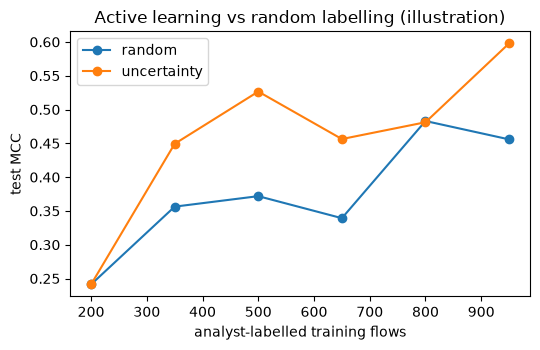

In [21]:
def active_learning(seed=SEED, init=200, step=150, rounds=AL_ROUNDS):
    d = preprocess(seed); S = states(d["Atr"] * BW); Ste = states(d["Ate"] * BW)
    r = np.random.default_rng(seed)
    start = np.sort(train_test_split(np.arange(len(d["ytr"])), train_size=init, stratify=d["ytr"], random_state=seed)[0])
    out = {}
    for strategy in ["uncertainty", "random"]:
        lab = start.copy(); hist = []
        for rd in range(rounds + 1):
            q = QRF(seed=seed + rd, tries=1).fit(S, d["ytr"], rows=lab)
            pred = q.predict(Ste)
            hist.append(dict(strategy=strategy, round=rd, labelled=len(lab), test_mcc=matthews_corrcoef(d["yte"], pred), test_acc=accuracy_score(d["yte"], pred) * 100))
            if rd == rounds: break
            pool = np.setdiff1d(np.arange(len(d["ytr"])), lab)
            if strategy == "uncertainty":
                pr = q.proba(S[pool]); pick = pool[np.argsort(np.abs(pr[:, 1] - pr[:, 0]))[:step]]     # least confident
            else:
                pick = r.choice(pool, step, replace=False)
            lab = np.union1d(lab, pick)
        out[strategy] = pd.DataFrame(hist)
    return pd.concat(out.values())

al = active_learning()
display(al.pivot(index="labelled", columns="strategy", values=["test_mcc", "test_acc"]).round(3))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for s, g in al.groupby("strategy"): ax.plot(g["labelled"], g["test_mcc"], marker="o", label=s)
ax.set_xlabel("analyst-labelled training flows"); ax.set_ylabel("test MCC"); ax.legend(); ax.set_title("Active learning vs random labelling (illustration)")
plt.tight_layout(); plt.show()

In [22]:
if RUN_ABLATIONS:
    abl = []
    for T in [1, 3, 10]:           abl.append(run_one(SEED, None, T=T) | {"variant": f"trees={T}"})
    for L in [5, 10, 20]:          abl.append(run_one(SEED, None, L=L) | {"variant": f"landmarks={L}"})
    for dep in [2, 4, 6]:          abl.append(run_one(SEED, None, depth=dep) | {"variant": f"depth={dep}"})
    for tr_ in [1, 5, 10]:         abl.append(run_one(SEED, None, tries=tr_) | {"variant": f"split tries={tr_}"})
    display(pd.DataFrame(abl)[["variant", "acc", "f1_att", "f1_norm", "mcc", "fit_s"]].round(3))
else:
    print("Ablations (trees, landmarks, depth, split tries) run only when FAST_MODE = False.")

,variant,acc,f1_att,f1_norm,mcc,fit_s
0,trees=1,92.672,60.915,95.957,0.617,1.844
1,trees=3,92.843,63.038,96.038,0.629,8.596
2,trees=10,93.039,63.776,96.150,0.640,21.953
3,landmarks=5,92.843,63.038,96.038,0.629,6.908
4,landmarks=10,92.917,63.278,96.080,0.633,12.329
5,landmarks=20,93.064,64.041,96.162,0.642,13.972
6,depth=2,92.794,62.972,96.009,0.626,3.182
7,depth=4,92.843,63.038,96.038,0.629,8.876
8,depth=6,93.137,64.103,96.206,0.646,14.248
9,split tries=1,92.770,62.986,95.993,0.625,1.553


## 11. Side-by-side comparison with the paper

Verdict rule: "reproduced" when the notebook's mean is within 2 percentage points (0.02 for MCC) of the paper's value,
"not reached" when it is lower by more, "exceeded" when higher by more, "cannot be checked" when the claim concerns data or a
manual workflow that this notebook does not have. Precision, recall and F1 are taken with the **normal** class positive,
the reading under which the paper's own numbers are mutually consistent (section 7a); the attack-positive values are
printed next to them.

In [23]:
def mean_of(df, eps, col): return float(df[df["eps"].astype(str) == str(eps)][col].mean())
def verdict(paper, mine, tol=2.0):
    gap = mine - paper
    return "reproduced" if abs(gap) <= tol else (f"not reached (gap {gap:+.2f})" if gap < 0 else f"exceeded (gap {gap:+.2f})")

paper = {"none": dict(acc=99.93, prec=99.92, rec=100.0, f1=99.96), str(EPSILON): dict(acc=99.90, prec=99.89, rec=100.0, f1=99.94)}
rows = []
for key, label in [("none", "without LDP"), (str(EPSILON), "with LDP (eps=1)")]:
    for m, col, colatt in [("accuracy", "acc", "acc"), ("precision", "prec_norm", "prec_att"), ("recall", "rec_norm", "rec_att"), ("F1", "f1_norm", "f1_att")]:
        pv = paper[key][{"acc": "acc", "prec_norm": "prec", "rec_norm": "rec", "f1_norm": "f1"}[col]]
        mv = mean_of(main, key, col)
        rows.append(dict(claim=f"WUSTL-EHMS {label}: {m} (%)", paper=pv, notebook=round(mv, 2),
                         notebook_attack_positive=round(mean_of(main, key, colatt), 2), verdict=verdict(pv, mv)))
mcc_nl, mcc_l = mean_of(main, "none", "mcc"), mean_of(main, str(EPSILON), "mcc")
rows.append(dict(claim="MCC without LDP (Fig. 5, band 0.97-0.99)", paper=0.97, notebook=round(mcc_nl, 3), notebook_attack_positive=round(mcc_nl, 3), verdict=verdict(0.97, mcc_nl, 0.02)))
rows.append(dict(claim="MCC with LDP (Fig. 5, band 0.97-0.99)", paper=0.97, notebook=round(mcc_l, 3), notebook_attack_positive=round(mcc_l, 3), verdict=verdict(0.97, mcc_l, 0.02)))
drop = mean_of(main, "none", "acc") - mean_of(main, str(EPSILON), "acc")
rows.append(dict(claim="LDP costs almost no accuracy on WUSTL (paper: 0.03 points)", paper=0.03, notebook=round(drop, 2), notebook_attack_positive=np.nan,
                 verdict="reproduced" if abs(drop - 0.03) <= 2.0 else "not reproduced"))
rf_gap = base[(base.eps.astype(str) == "none") & (base.model == "RF-100 (6 PCA)")]["acc"].mean() - mean_of(main, "none", "acc")
rows.append(dict(claim="QRF close to classical RF (paper, ICU: RF 1.42 points better)", paper=1.42, notebook=round(rf_gap, 2), notebook_attack_positive=np.nan,
                 verdict="reproduced (gap on WUSTL, not ICU)" if abs(rf_gap - 1.42) <= 2.0 else "differs"))
idr = id_df[id_df.eps.astype(str) == "none"]
rows.append(dict(claim="WUSTL accuracy when SrcMac/Flgs/Sport are kept (33 features, QRF, no LDP)", paper=99.93, notebook=round(idr["acc"].mean(), 2),
                 notebook_attack_positive=round(idr["acc"].mean(), 2), verdict=verdict(99.93, idr["acc"].mean())))
rows.append(dict(claim="ICU dataset results (Table II, IV; Fig. 4, 5)", paper=np.nan, notebook=np.nan, notebook_attack_positive=np.nan, verdict="cannot be checked (no public ICU data)"))
rows.append(dict(claim="Table III formulas (PCA 11.07M, QKE 7.93B, QRF 5625)", paper=7.93e9, notebook=float(qke_t), notebook_attack_positive=np.nan,
                 verdict="reproduced (QKE, QRF exact; PCA 11.04M vs 11.07M)"))
rows.append(dict(claim="ChatGPT labels 3 of 5 ICU MQTT records correctly", paper=np.nan, notebook=np.nan, notebook_attack_positive=np.nan, verdict="cannot be checked (manual workflow, ICU data)"))
comp = pd.DataFrame(rows)
for c_ in ["paper", "notebook", "notebook_attack_positive"]:
    comp[c_] = [("-" if pd.isna(v) else f"{v:.4g}") for v in comp[c_]]
pd.set_option("display.max_colwidth", 90)
display(comp)

,claim,paper,notebook,notebook_attack_positive,verdict
0,WUSTL-EHMS without LDP: accuracy (%),99.93,92.35,92.35,not reached (gap -7.58)
1,WUSTL-EHMS without LDP: precision (%),99.92,92.5,90.41,not reached (gap -7.42)
2,WUSTL-EHMS without LDP: recall (%),100,99.32,43.83,reproduced
3,WUSTL-EHMS without LDP: F1 (%),99.96,95.78,58.92,not reached (gap -4.18)
4,WUSTL-EHMS with LDP (eps=1): accuracy (%),99.9,92.35,92.35,not reached (gap -7.55)
5,WUSTL-EHMS with LDP (eps=1): precision (%),99.89,92.5,90.41,not reached (gap -7.39)
6,WUSTL-EHMS with LDP (eps=1): recall (%),100,99.32,43.83,reproduced
7,WUSTL-EHMS with LDP (eps=1): F1 (%),99.94,95.78,58.92,not reached (gap -4.16)
8,"MCC without LDP (Fig. 5, band 0.97-0.99)",0.97,0.597,0.597,not reached (gap -0.37)
9,"MCC with LDP (Fig. 5, band 0.97-0.99)",0.97,0.597,0.597,not reached (gap -0.37)


## 12. Reading the paper critically

* **The headline accuracy rests on a dataset shortcut, not on the quantum model.** WUSTL-EHMS-2020 contains the attacker's
  MAC address; with it any model is perfect (section 7), without it a classical random forest also stays near 94 %. The paper
  itself notes that its datasets are "relatively easy", but does not say which columns it kept; the 99.93 % cannot be reached
  from the 30 traffic and vital-sign features the paper says it used. Even the full pipeline with the identifier columns added back (section 7) stays near 96 % here, because PCA to six components dilutes the one column that carries the shortcut, whereas a random forest on the 33 raw columns is perfect; so no pipeline tried here reaches 99.9 % without exposing the attacker's MAC address to the model directly, and why the paper got there remains unexplained. Even the full pipeline with the identifier columns added back (section 7) stays near 96 % here, because PCA to six components dilutes the one column that carries the shortcut, whereas a random forest on the 33 raw columns is perfect; so no pipeline tried here reaches 99.9 % without exposing the attacker's MAC address to the model directly, and why the paper got there remains unexplained.
* **The privacy layer, as specified, cannot change the detector's input.** Algorithm 1 adds Laplace noise to the *mean*
  used for standardisation: one value per feature, the same shift for every record, with the sensitivity of a mean over n
  records. A constant shift of all records is removed again by the PCA centring and the min-max scaling, so the QRF with and
  without "LDP" receives numerically identical inputs (section 8 prints the maximum difference) and the two result rows of
  section 6 are identical, which is why the paper finds almost no accuracy cost. This is not record-level local differential
  privacy (which would randomise each record before it leaves the device); a record's own value stays fully visible, and the
  paper's 0.03-point loss says nothing about the utility cost of real LDP (exercise 4).
* **The metric convention matters.** The paper's precision, recall and accuracy are mutually consistent only with the
  majority (normal) class as positive. With attacks as positive, recall of attacks is the quantity a defender cares about.
* **No quantum advantage is shown.** The paper compares only with LR and NB (and RF) on the ICU data; here a 3-tree classical
  forest of depth 4 on the same six inputs matches the QRF. A kernel on 6 qubits is classically simulable (this notebook
  does exactly that), and the Nystroem step with 5 landmarks bounds the split's flexibility.
* **Missing details.** Table I (an image) is not extractable; feature map, bandwidth, landmark selection and SVM regularisation
  are not specified, so the QRF here is a faithful but not identical implementation.
* **The human-centred part is not evaluated.** Active learning, threat intelligence and ChatGPT are described and shown on
  five ICU records; no experiment measures their effect. Section 10 is only an illustration.
* **Seeds and error bars.** The paper gives a single run; we report means and standard deviations over seeds.

## 13. Exercises

1. Set `CLASS_WEIGHT = None` and `SPLIT_TRIES = 1` (the literal paper). How do accuracy, recall of attacks and MCC change, and why?
2. Replace the ZZ feature map by `z_feature_map` (no entanglement) in `states`. Does the kernel still help? (Hint: compare with an RBF-SVM.)
3. Use `Atr` without the bandwidth (`BW = 1`) and with `BW = 0.05`: plot the mean off-diagonal kernel value against the bandwidth and explain the trend.
4. Implement a real record-level local-DP mechanism (Laplace noise with scale `range_j / epsilon` added to every record's features before scaling).
   How large must epsilon be before the QRF keeps its accuracy?
5. Change `active_learning` to query the records with highest *attack* probability instead of the least certain ones. Which strategy finds more attacks per label?